# UTS Graf Sains Data
### **Nama:** Kartika Nur Savira 
### **NIM:** [24031554049] 
### **Kelas:** 2024B
**Dataset:** RetailRocket (events.csv) | **Database:** Neo4j (driver Python)  
**Kombinasi periode:** no.16, P1 = 01-15 Juni 2015 (training), P2 = 16-30 Juni 2015 (testing)


---
## 1. Tugas Pendahuluan & Checkpoint (Halaman 2 PDF)

### Jawaban Pertanyaan Pendahuluan (Checkpoint):
1. **Apa nama database yang digunakan pada tutorial ini?**
- Nama database yang digunakan adalah neo4j. Hal ini terlihat secara eksplisit pada parameter eksekusi query di tutorial, yaitu `database_="neo4j"`.

2. **Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**
  
- Akses lain untuk mengakses database berbeda dalam satu instance Neo4j dapat dilakukan melalui parameter `database_` pada Python Driver dan sintaks administrasi Cypher. Contohnya, `session = driver.session(database="nama_db")` untuk memilih database tujuan, `SHOW DATABASES` untuk melihat daftar database, serta `CREATE DATABASE namaDb` untuk membuat database baru.
3. **Apa jenis graf pertemanan yang telah dibuat di sini?**

 - Graf yang dibuat adalah graf berarah (directed graph) dan tidak berbobot (unweighted graph), dengan simpul berupa orang (`Person`) dan sisi berupa relasi pertemanan (`KNOWS`).
---


## Preparation


### Cek Python & Driver Neo4j


In [1]:
import sys
import neo4j

print("Python executable:", sys.executable)
print("Neo4j driver ver :", neo4j.__version__)


Python executable: /Users/savv/UTS GRAF/myvenv/bin/python
Neo4j driver ver : 4.2.1


### Konfigurasi & Uji Koneksi Database Neo4j


In [2]:
from getpass import getpass
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))

# Uji koneksi ke Neo4j
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")


Koneksi ke Neo4j berhasil!


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_9359/3929447550.py:9: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


---
### Eksplorasi Awal Dataset RetailRocket (`events.csv`)
---


In [3]:
import pandas as pd
import numpy as np

# Membaca seluruh data interaksi dari events.csv
df = pd.read_csv("data/events.csv")
print("Dimensi dataset events.csv:", df.shape)
df.head()


Dimensi dataset events.csv: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 105.1 MB


### Cek Missing Value & Duplikat


In [5]:
print("Jumlah Missing Value per Kolom:")
print(df.isna().sum())

print("\nJumlah Baris Duplikat:", df.duplicated().sum())


Jumlah Missing Value per Kolom:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

Jumlah Baris Duplikat: 460


### Distribusi Jenis Event


In [6]:
# Menampilkan frekuensi dan proporsi masing-masing event
distribusi_event = pd.DataFrame({
    "Jumlah": df["event"].value_counts(),
    "Persentase": df["event"].value_counts(normalize=True).apply(lambda x: f"{x:.2%}")
})
display(distribusi_event)


,Jumlah,Persentase
event,,
view,2664312,96.67%
addtocart,69332,2.52%
transaction,22457,0.81%


### Validasi Konsistensi Kolom `transactionid`


In [7]:
# Memastikan transactionid hanya terisi saat event berjenis 'transaction'
terisi_saat_transaksi = df[df["event"] == "transaction"]["transactionid"].notna().all()
terisi_saat_lain = df[df["event"] != "transaction"]["transactionid"].notna().sum()

print("transactionid selalu terisi saat event transaction:", terisi_saat_transaksi)
print("transactionid terisi pada event selain transaction :", terisi_saat_lain)


transactionid selalu terisi saat event transaction: True
transactionid terisi pada event selain transaction : 0


### Konversi Timestamp ke Datetime


In [8]:
# Konversi unix epoch milidetik ke datetime
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")

display(pd.DataFrame({
    "Metrik": ["Waktu Awal", "Waktu Akhir", "Total Durasi Data"],
    "Nilai": [df["dt"].min(), df["dt"].max(), df["dt"].max() - df["dt"].min()]
}))


,Metrik,Nilai
0,Waktu Awal,2015-05-03 03:00:04.384000
1,Waktu Akhir,2015-09-18 02:59:47.788000
2,Total Durasi Data,137 days 23:59:43.404000


### Sebaran Event per Bulan


In [9]:
df.groupby(df["dt"].dt.to_period("M")).size().to_frame("Jumlah Event")


,Jumlah Event
dt,
2015-05,590652
2015-06,610393
2015-07,697984
2015-08,553362
2015-09,303710


### Jumlah User & Item Unik


In [10]:
display(df[["visitorid", "itemid"]].nunique().to_frame("Jumlah Unik"))

per_user = df.groupby("visitorid").size()
display(per_user.describe().to_frame("Statistik Interaksi per User"))
display(pd.DataFrame({"User dengan hanya 1 interaksi": [f"{(per_user == 1).mean():.2%}"]}))


,Jumlah Unik
visitorid,1407580
itemid,235061


,Statistik Interaksi per User
count,1.407580e+06
mean,1.958042e+00
std,1.258049e+01
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,2.000000e+00
max,7.757000e+03


,User dengan hanya 1 interaksi
0,71.15%


### Ringkasan Entitas Unik per Jenis Event


In [11]:
summary = df.groupby("event").agg(
    unique_visitor=("visitorid", "nunique"),
    unique_item=("itemid", "nunique")
).reset_index()

display(summary)


,event,unique_visitor,unique_item
0,addtocart,37722,23903
1,transaction,11719,12025
2,view,1404179,234838


---
### 2.1 Wrangling dan EDA (Maks. skor: 45)

#### Soal 2.1 No. 1 & 2: Penentuan Periode Waktu & Penyimpanan ke File CSV
Kombinasi periode yang digunakan adalah **no. 16**:
- **Fold Training (P1):** `01 Juni 2015` s/d `15 Juni 2015` (15 hari)
- **Fold Testing (P2):** `16 Juni 2015` s/d `30 Juni 2015` (15 hari)

Data difilter berdasarkan kolom datetime (`dt`) dan disimpan ke dalam berkas `data/item_properties_p1.csv` dan `data/item_properties_p2.csv`.


In [12]:
# 1. Rentang periode no. 16
P1_RANGE = ("2015-06-01", "2015-06-15")   # Training (P1)
P2_RANGE = ("2015-06-16", "2015-06-30")   # Testing (P2)

# Fungsi cut data berdasarkan tanggal
def filter_periode(data, t_awal, t_akhir):
    awal = pd.Timestamp(t_awal)
    akhir = pd.Timestamp(t_akhir) + pd.Timedelta(days=1)
    return data[(data["dt"] >= awal) & (data["dt"] < akhir)].drop(columns=["dt"])

p1 = filter_periode(df, *P1_RANGE)
p2 = filter_periode(df, *P2_RANGE)

print("Dimensi Data P1 (Training):", p1.shape)
print("Dimensi Data P2 (Testing) :", p2.shape)
print("Visitor unik P1:", p1["visitorid"].nunique(), "| Visitor unik P2:", p2["visitorid"].nunique())
print("Visitor yang muncul di kedua periode:", len(set(p1["visitorid"]) & set(p2["visitorid"])))


Dimensi Data P1 (Training): (300563, 5)
Dimensi Data P2 (Testing) : (309830, 5)
Visitor unik P1: 160017 | Visitor unik P2: 161249
Visitor yang muncul di kedua periode: 7434


In [13]:
print("Rentang Tanggal P1:", df.loc[p1.index, "dt"].min(), "s/d", df.loc[p1.index, "dt"].max())
print("Rentang Tanggal P2:", df.loc[p2.index, "dt"].min(), "s/d", df.loc[p2.index, "dt"].max())
print("Overlap baris antara P1 dan P2:", len(set(p1.index) & set(p2.index)))


Rentang Tanggal P1: 2015-06-01 00:00:01.707000 s/d 2015-06-15 23:59:58.941000
Rentang Tanggal P2: 2015-06-16 00:00:01.724000 s/d 2015-06-30 23:59:59.292000
Overlap baris antara P1 dan P2: 0


In [14]:
# Simpan ke berkas CSV sesuai instruksi Soal No. 2
p1.to_csv("data/item_properties_p1.csv", index=False)
p2.to_csv("data/item_properties_p2.csv", index=False)
print("File data/item_properties_p1.csv dan data/item_properties_p2.csv berhasil disimpan!")


File data/item_properties_p1.csv dan data/item_properties_p2.csv berhasil disimpan!


#### Soal 2.1 No. 3: Query Komposisi Subgraph & Penjelasan CYPHER

Data training P1 diimpor ke Neo4j dengan `import_data.py`. Komposisi subgraph diambil melalui Python API (driver Neo4j, `session.run`) dan hasilnya ditampilkan pada dua tabel di bawah. Subgraph memiliki dua jenis simpul, yaitu `Visitor` dan `Item`, serta tiga jenis relasi interaksi: `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Total relasi sama dengan jumlah baris P1, sehingga tidak ada event yang hilang saat impor.


In [15]:
def run(query, **params):
    with GraphDatabase.driver(URI, auth=AUTH) as driver:
        with driver.session(database="neo4j") as session:
            return pd.DataFrame(session.run(query, **params).data())

In [16]:
n_rel = int(run("MATCH ()-[r]->() WHERE type(r) <> 'SIMILAR' RETURN count(r) AS n")["n"][0])
print("Relasi interaksi di Neo4j:", n_rel, "| Baris P1:", len(p1))
assert n_rel == len(p1), "Graf tidak sama dengan P1. Jalankan ulang import_data.py dengan --reset."

Relasi interaksi di Neo4j: 300563 | Baris P1: 300563


In [17]:
simpul = run("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah")
relasi = run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah")

print("Komposisi simpul:")
display(simpul)
print("Komposisi relasi:")
display(relasi)

Komposisi simpul:


,label,jumlah
0,Visitor,160017
1,Item,79896


Komposisi relasi:


,relasi,jumlah
0,VIEWED,291122
1,ADDED_TO_CART,7110
2,BOUGHT,2331


In [18]:
jumlah = simpul.set_index("label")["jumlah"]
print("Visitor di graf:", jumlah["Visitor"], "| unik di P1:", p1["visitorid"].nunique())
print("Item di graf   :", jumlah["Item"], "| unik di P1:", p1["itemid"].nunique())
print("Total relasi   :", relasi["jumlah"].sum(), "| baris P1:", len(p1))

Visitor di graf: 160017 | unik di P1: 160017
Item di graf   : 79896 | unik di P1: 79896
Total relasi   : 300563 | baris P1: 300563



**CYPHER yang digunakan:**

1. Komposisi simpul
```cypher
   MATCH (n)
   RETURN labels(n)[0] AS label, count(*) AS jumlah
```
   - `MATCH (n)` mengambil seluruh simpul pada graf.
   - `labels(n)[0]` mengambil label tiap simpul (`Visitor` atau `Item`).
   - `count(*)` menghitung jumlah per label. Kolom `label` otomatis menjadi kunci pengelompokan (agregasi implisit, setara `GROUP BY` di SQL).

2. Komposisi relasi
```cypher
   MATCH ()-[r]->()
   RETURN type(r) AS relasi, count(*) AS jumlah
```
   - `MATCH ()-[r]->()` mencocokkan semua relasi berarah di antara dua simpul.
   - `type(r)` mengambil jenis relasi, dan `count(*)` menghitung jumlahnya per jenis.

#### Soal 2.1 No. 4: Vector Space Modelling (VSM) Simpul User

Graf bipartit `Visitor → Item` diubah menjadi matriks interaksi **User × Item**. Tiap baris adalah satu user (vektor), tiap kolom adalah satu item (dimensi), dan nilainya bobot interaksi: `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5 (dijumlahkan jika user berinteraksi berulang dengan item yang sama). Matriks disimpan sebagai `csr_matrix` karena hampir seluruh selnya nol.

**Plot networkx** di bawah menunjukkan sampel 15 user (biru) beserta item yang mereka interaksi (oranye). Grafnya bipartit: tidak ada sisi user–user atau item–item, user hanya terhubung ke item. Karena itu satu plot ini berlaku untuk no.4 (sisi user) dan no.5 (sisi item).

### Bangun matriks User × Item

In [19]:
from scipy.sparse import csr_matrix
from IPython.display import Markdown

q = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS user, i.itemId AS item, type(r) AS relasi, count(*) AS n
"""
d = run(q)
d["bobot"] = d["relasi"].map({"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}) * d["n"]
d = d.groupby(["user", "item"], as_index=False)["bobot"].sum()

u_idx = {u: k for k, u in enumerate(d["user"].unique())}   # userId -> indeks baris
i_idx = {i: k for k, i in enumerate(d["item"].unique())}   # itemId -> indeks kolom
inv_i = {k: int(i) for i, k in i_idx.items()}              # indeks kolom -> itemId

X = csr_matrix((d["bobot"], (d["user"].map(u_idx), d["item"].map(i_idx))),
               shape=(len(u_idx), len(i_idx)))
print("X (User x Item):", X.shape, "| pasangan user-item unik:", X.nnz)

X (User x Item): (160017, 79896) | pasangan user-item unik: 234959


### Karakteristik VSM User

In [20]:
def angka(x, desimal=0):
    """Format angka gaya Indonesia: 1.234,56"""
    return f"{x:,.{desimal}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def karakteristik(M, nama_baris, nama_kolom):
    total = M.shape[0] * M.shape[1]
    per_baris = np.diff(M.indptr)
    return {
        f"Baris ({nama_baris})": M.shape[0],
        f"Kolom ({nama_kolom})": M.shape[1],
        "NNZ": M.nnz,
        "Density (%)": M.nnz / total * 100,
        "Sparsity (%)": 100 - M.nnz / total * 100,
        "Memori Sparse (MB)": (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6,
        f"Rata-rata Interaksi per {nama_baris}": per_baris.mean(),
    }

ku = karakteristik(X, "User", "Item")
display(pd.Series(ku, name="VSM User").to_frame())


,VSM User
Baris (User),160017.000000
Kolom (Item),79896.000000
NNZ,234959.000000
Density (%),0.001838
Sparsity (%),99.998162
Memori Sparse (MB),3.459580
Rata-rata Interaksi per User,1.468338


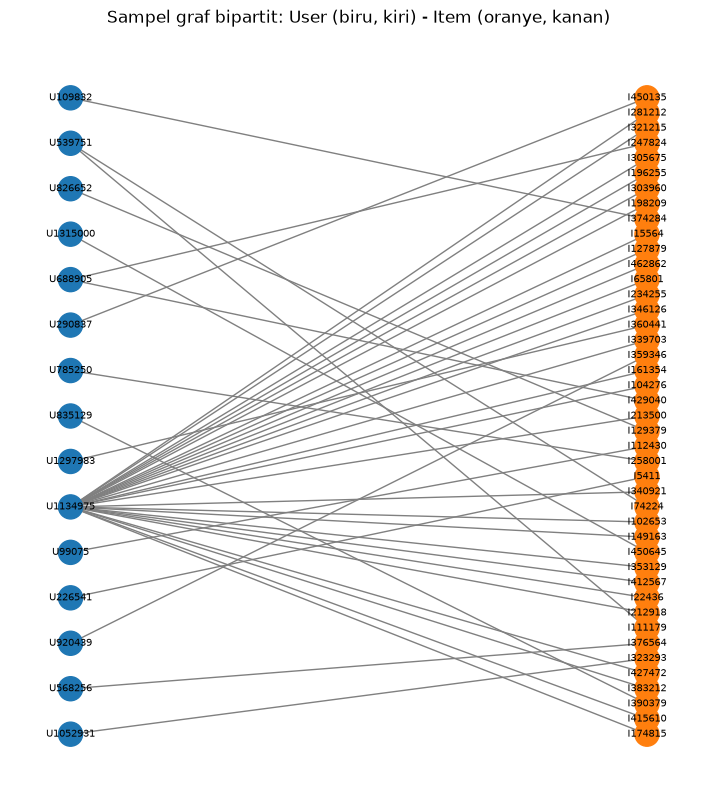

Simpul: 58 | Sisi: 43


In [21]:
import networkx as nx
import matplotlib.pyplot as plt

user_s = d["user"].drop_duplicates().sample(15, random_state=42)     # sampel 15 user
sub = d[d["user"].isin(user_s)].copy()
sub["user"] = "U" + sub["user"].astype(str)                          
sub["item"] = "I" + sub["item"].astype(str)

G = nx.from_pandas_edgelist(sub, "user", "item", edge_attr="bobot")
user_nodes = [n for n in G if n.startswith("U")]
warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G]

plt.figure(figsize=(9, 10))
nx.draw_networkx(G, pos=nx.bipartite_layout(G, user_nodes), node_color=warna,
                 node_size=300, font_size=7, edge_color="gray")
plt.title("Sampel graf bipartit: User (biru, kiri) - Item (oranye, kanan)")
plt.axis("off")
plt.show()
print("Simpul:", G.number_of_nodes(), "| Sisi:", G.number_of_edges())

#### Soal 2.1 No. 5: Vector Space Modelling (VSM) Simpul Item

VSM Item adalah matriks interaksi yang sama dengan no.4 tetapi dilihat dari sisi item (transpose): tiap baris adalah satu item (vektor), tiap kolom adalah satu user (dimensi), dan nilainya tetap bobot interaksi (`VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5). Vektor item menggambarkan "siapa saja yang berinteraksi dengan item ini", sehingga dua item dianggap mirip jika diminati user yang sama.

**Plot networkx** di bawah menampilkan sampel 8 item (oranye) beserta user yang berinteraksi dengannya (biru). Item yang dipilih punya 3 sampai 10 user agar grafnya terbaca.

VSM Item dan karakteristiknya

In [22]:
XT = X.T.tocsr()
ki = karakteristik(XT, "Item", "User")
display(pd.Series(ki, name="VSM Item").to_frame())

,VSM Item
Baris (Item),79896.000000
Kolom (User),160017.000000
NNZ,234959.000000
Density (%),0.001838
Sparsity (%),99.998162
Memori Sparse (MB),3.139096
Rata-rata Interaksi per Item,2.940811


In [23]:
display(Markdown(f"""
**Karakteristik VSM Item:**
- **Dimensi / shape:** tiap item adalah vektor berdimensi **{angka(ki['Kolom (User)'])}** (jumlah user); shape matriks **({angka(ki['Baris (Item)'])} × {angka(ki['Kolom (User)'])})**.
- **Elemen non-zero (NNZ):** {angka(ki['NNZ'])}, sama dengan VSM User karena hanya transpose.
- **Density / sparsity:** {angka(ki['Density (%)'], 4)}% / {angka(ki['Sparsity (%)'], 4)}%, juga sama dengan VSM User.
- **Memori sparse:** {angka(ki['Memori Sparse (MB)'], 2)} MB.
- **Interaksi per item:** rata-rata {angka(ki['Rata-rata Interaksi per Item'], 2)} user per item.
"""))


**Karakteristik VSM Item:**
- **Dimensi / shape:** tiap item adalah vektor berdimensi **160.017** (jumlah user); shape matriks **(79.896 × 160.017)**.
- **Elemen non-zero (NNZ):** 234.959, sama dengan VSM User karena hanya transpose.
- **Density / sparsity:** 0,0018% / 99,9982%, juga sama dengan VSM User.
- **Memori sparse:** 3,14 MB.
- **Interaksi per item:** rata-rata 2,94 user per item.


Plot networkx dari sisi item

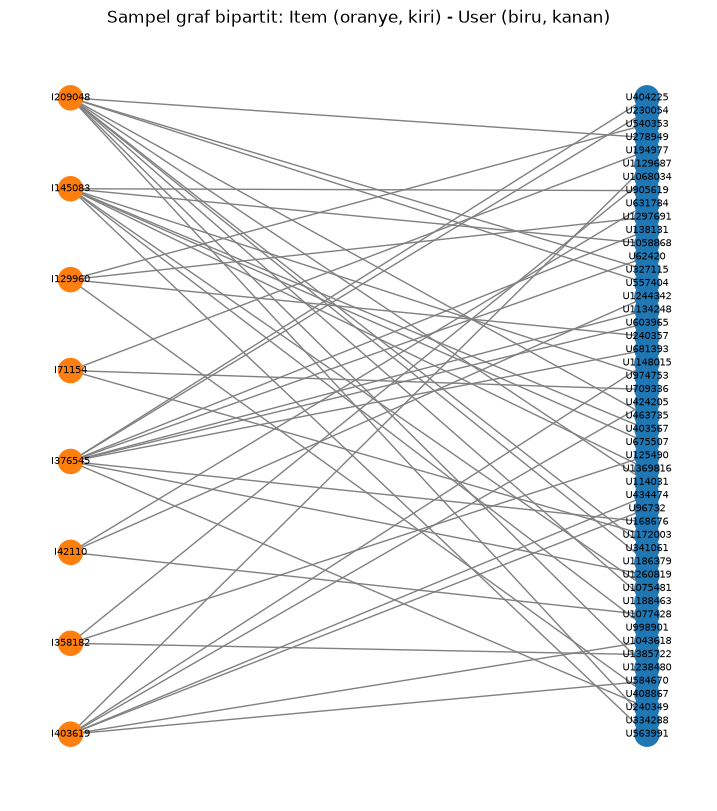

Simpul: 57 | Sisi: 49


In [24]:
user_per_item = d.groupby("item").size()
item_s = user_per_item[(user_per_item >= 3) & (user_per_item <= 10)].sample(8, random_state=42).index

sub = d[d["item"].isin(item_s)].copy()
sub["user"] = "U" + sub["user"].astype(str)
sub["item"] = "I" + sub["item"].astype(str)

G2 = nx.from_pandas_edgelist(sub, "item", "user", edge_attr="bobot")
item_nodes = [n for n in G2 if n.startswith("I")]
warna = ["tab:orange" if n.startswith("I") else "tab:blue" for n in G2]

plt.figure(figsize=(9, 10))
nx.draw_networkx(G2, pos=nx.bipartite_layout(G2, item_nodes), node_color=warna,
                 node_size=300, font_size=7, edge_color="gray")
plt.title("Sampel graf bipartit: Item (oranye, kiri) - User (biru, kanan)")
plt.axis("off")
plt.show()
print("Simpul:", G2.number_of_nodes(), "| Sisi:", G2.number_of_edges())

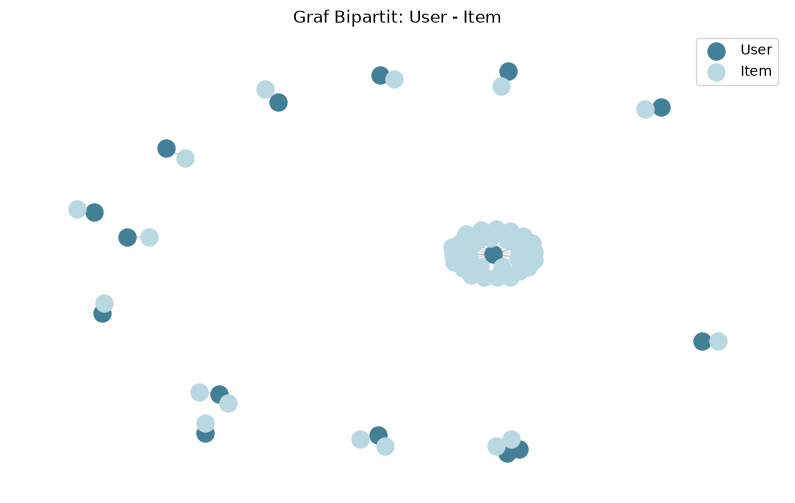

In [25]:
plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(G, pos, nodelist=user_nodes,
                       node_color="#447F98", node_size=150, label="User")
nx.draw_networkx_nodes(G, pos, nodelist=[n for n in G if n.startswith("I")],
                       node_color="#B9D8E1", node_size=150, label="Item")
nx.draw_networkx_edges(G, pos, alpha=0.3, edge_color="gray")

plt.title("Graf Bipartit: User - Item")
plt.legend(scatterpoints=1)
plt.axis("off")
plt.show()

Bangun kedua proyeksi dan bandingkan

In [26]:
B = X.copy()
B.data[:] = 1                      # biner: ada interaksi atau tidak
UU = (B @ B.T).tocsr()             # proyeksi User-User (dua user terhubung jika berbagi item)
II = (B.T @ B).tocsr()             # proyeksi Item-Item (dua item terhubung jika berbagi user)

def profil(M):
    n = M.shape[0]
    tetangga = np.diff(M.indptr) - 1          # buang diagonal (diri sendiri)
    pasangan = int(tetangga.sum() // 2)
    return {
        "Simpul": n,
        "Pasangan terhubung": pasangan,
        "Density (%)": pasangan / (n * (n - 1) / 2) * 100,
        "Simpul tanpa tetangga (%)": (tetangga == 0).mean() * 100,
        "Tetangga rata-rata": tetangga.mean(),
        "Tetangga median": np.median(tetangga),
        "Tetangga maks": tetangga.max(),
    }

pu, pit = profil(UU), profil(II)
display(pd.DataFrame({"User-User": pu, "Item-Item": pit}).round(6))

,User-User,Item-Item
Simpul,1.600170e+05,7.989600e+04
Pasangan terhubung,1.855033e+06,1.069339e+06
Density (%),1.448900e-02,3.350400e-02
Simpul tanpa tetangga (%),1.882987e+01,4.865325e+01
Tetangga rata-rata,2.318545e+01,2.676827e+01
Tetangga median,5.000000e+00,1.000000e+00
Tetangga maks,4.604000e+03,3.516000e+03


#### Soal 2.1 No. 6: Proyeksi yang Lebih Baik

Dari matriks interaksi biner `B` (User × Item) dibentuk dua proyeksi graf: **User-User** (`B Bᵀ`, dua user terhubung jika pernah berinteraksi dengan item yang sama) dan **Item-Item** (`Bᵀ B`, dua item terhubung jika pernah diinteraksi user yang sama). Keduanya dibandingkan dari sisi efisiensi (jumlah simpul dan sisi) dan efektivitas (kepadatan, rata-rata tetangga, dan simpul yang terisolasi).

In [27]:
ruang_u = pu["Simpul"] * (pu["Simpul"] - 1) / 2
ruang_i = pit["Simpul"] * (pit["Simpul"] - 1) / 2
display(Markdown(f"""
**Uraian & kesimpulan: proyeksi Item-Item lebih baik**
- **Proyeksi User-User:** {angka(pu['Simpul'])} simpul, {angka(pu['Pasangan terhubung'])} sisi (density {angka(pu['Density (%)'], 4)}%), ruang pasangan yang harus dihitung ≈ {angka(ruang_u / 1e9, 1)} miliar.
- **Proyeksi Item-Item:** {angka(pit['Simpul'])} simpul, {angka(pit['Pasangan terhubung'])} sisi (density {angka(pit['Density (%)'], 4)}%), ruang pasangan ≈ {angka(ruang_i / 1e9, 1)} miliar.

**Alasan Item-Item lebih efektif dan efisien:**
1. **Efisiensi komputasi:** jumlah simpul item hanya {angka(pit['Simpul'] / pu['Simpul'] * 100)}% dari simpul user, dan sisinya {angka((1 - pit['Pasangan terhubung'] / pu['Pasangan terhubung']) * 100)}% lebih sedikit, sehingga perhitungan similarity lebih cepat dan hemat memori.
2. **Kepadatan lebih tinggi:** density Item-Item {angka(pit['Density (%)'] / pu['Density (%)'], 1)} kali lipat User-User, dengan rata-rata tetangga {angka(pit['Tetangga rata-rata'], 1)} (User-User: {angka(pu['Tetangga rata-rata'], 1)}).
3. **Stabilitas rekomendasi:** katalog barang lebih stabil daripada jumlah user yang terus bertambah, dan item-based collaborative filtering tidak perlu dihitung ulang saat user baru masuk.

*Catatan:* {angka(pit['Simpul tanpa tetangga (%)'], 2)}% item tidak punya tetangga (User-User: {angka(pu['Simpul tanpa tetangga (%)'], 2)}%) karena hanya diinteraksi satu user yang tidak berinteraksi dengan item lain, sehingga item tersebut mengalami cold-start.
"""))


**Uraian & kesimpulan: proyeksi Item-Item lebih baik**
- **Proyeksi User-User:** 160.017 simpul, 1.855.033 sisi (density 0,0145%), ruang pasangan yang harus dihitung ≈ 12,8 miliar.
- **Proyeksi Item-Item:** 79.896 simpul, 1.069.339 sisi (density 0,0335%), ruang pasangan ≈ 3,2 miliar.

**Alasan Item-Item lebih efektif dan efisien:**
1. **Efisiensi komputasi:** jumlah simpul item hanya 50% dari simpul user, dan sisinya 42% lebih sedikit, sehingga perhitungan similarity lebih cepat dan hemat memori.
2. **Kepadatan lebih tinggi:** density Item-Item 2,3 kali lipat User-User, dengan rata-rata tetangga 26,8 (User-User: 23,2).
3. **Stabilitas rekomendasi:** katalog barang lebih stabil daripada jumlah user yang terus bertambah, dan item-based collaborative filtering tidak perlu dihitung ulang saat user baru masuk.

*Catatan:* 48,65% item tidak punya tetangga (User-User: 18,83%) karena hanya diinteraksi satu user yang tidak berinteraksi dengan item lain, sehingga item tersebut mengalami cold-start.


#### Soal 2.1 No. 7: Similarity pada Graf Terproyeksi

Berdasarkan no.6, similarity dihitung pada proyeksi **Item-Item** memakai **cosine similarity** pada vektor item (bobot view=1, addtocart=3, transaction=5). Nilainya 0 sampai 1 dan memakai matriks sparse, sehingga hanya pasangan item yang punya user bersama yang dihitung. Item acuan adalah item dengan tetangga terbanyak (lihat output di atas).

**7(a): CYPHER untuk 5 record dengan similarity tertinggi** (`$id` = item acuan):
```cypher
MATCH (a:Item {itemId: $id})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS cosine_similarity
ORDER BY s.score DESC
LIMIT 5
```

**7(b): menuliskan kembali similarity ke graf** sebagai relasi `SIMILAR` berproperti `score`:
```cypher
UNWIND $pairs AS p
MATCH (a:Item {itemId: p.a}), (b:Item {itemId: p.b})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = p.score
```
`UNWIND` mengurai daftar pasangan, `MATCH` mencari dua simpul Item, `MERGE` membuat relasi hanya jika belum ada, dan `SET` menyimpan skor pada relasi.

In [28]:
from sklearn.preprocessing import normalize

Xn = normalize(XT)                         # normalisasi L2 per item, dot product = cosine
S = (Xn @ Xn.T).tocsr()                    # cosine similarity item-item (sparse)
S.setdiag(0)
S.eliminate_zeros()                        # buang similarity item dengan dirinya sendiri

print("Shape S:", S.shape, "| pasangan item dengan similarity > 0:", S.nnz // 2)
print("Cocok dengan proyeksi no.6:", S.nnz // 2 == pit["Pasangan terhubung"])

Shape S: (79896, 79896) | pasangan item dengan similarity > 0: 1069339
Cocok dengan proyeksi no.6: True


In [29]:
ref_row = int(np.argmax(np.diff(S.indptr)))      # item acuan: tetangga terbanyak
ref_id = inv_i[ref_row]

baris = S.getrow(ref_row)
urut = np.argsort(-baris.data, kind="stable")[:5]
top5 = [(inv_i[baris.indices[j]], float(baris.data[j])) for j in urut]

print(f"Item acuan: {ref_id} ({baris.nnz} tetangga)")
display(pd.DataFrame(top5, columns=["itemId", "cosine_similarity"]))

Item acuan: 119736 (3516 tetangga)


,itemId,cosine_similarity
0,186702,0.653099
1,444931,0.587262
2,425920,0.580902
3,456169,0.576101
4,150882,0.565629


#### Soal 2.1 No. 8: Kondisi Graf Sebelum dan Sesudah Perhitungan Similarity

Query berikut dijalankan di **Neo4j Browser** pada kedua kondisi (query sama, hanya isi graf yang berubah). Daftar itemId diisi item acuan dan 5 item termirip, dicetak oleh Cell "SEBELUM".

```cypher
MATCH (i:Item)
WHERE i.itemId IN [ITEM_ACUAN, TETANGGA_1, TETANGGA_2, TETANGGA_3, TETANGGA_4, TETANGGA_5]
OPTIONAL MATCH (i)-[s:SIMILAR]-(j:Item)
RETURN i, s, j;
```


In [30]:
run("MATCH ()-[s:SIMILAR]->() DELETE s")
q_jumlah = "MATCH (:Item {itemId: $id})-[s:SIMILAR]->() RETURN count(s) AS jumlah"
print("Relasi SIMILAR dari item acuan SEBELUM:", run(q_jumlah, id=ref_id)["jumlah"][0])

# Query untuk Neo4j Browser (jalankan sekarang untuk screenshot SEBELUM, lalu lagi setelah Cell 4)
ids = [ref_id] + [i for i, _ in top5]
print(f"""
MATCH (i:Item) WHERE i.itemId IN {ids}
OPTIONAL MATCH (i)-[s:SIMILAR]-(j:Item)
RETURN i, s, j;""")

Relasi SIMILAR dari item acuan SEBELUM: 0

MATCH (i:Item) WHERE i.itemId IN [119736, 186702, 444931, 425920, 456169, 150882]
OPTIONAL MATCH (i)-[s:SIMILAR]-(j:Item)
RETURN i, s, j;


In [31]:
q_tulis = """
UNWIND $pairs AS p
MATCH (a:Item {itemId: p.a}), (b:Item {itemId: p.b})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = p.score
"""
pairs = [{"a": ref_id, "b": b, "score": s} for b, s in top5]

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        ringkasan = session.run(q_tulis, pairs=pairs).consume()
print("Relasi SIMILAR dibuat:", ringkasan.counters.relationships_created,
      "| properti diset:", ringkasan.counters.properties_set)

# No. 7(a) dan kondisi SESUDAH: baca kembali dari graf
display(run("""
MATCH (a:Item {itemId: $id})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS cosine_similarity
ORDER BY s.score DESC
LIMIT 5
""", id=ref_id))

Relasi SIMILAR dibuat: 5 | properti diset: 5


,item_acuan,item_mirip,cosine_similarity
0,119736,186702,0.653099
1,119736,444931,0.587262
2,119736,425920,0.580902
3,119736,456169,0.576101
4,119736,150882,0.565629


#### Soal 2.2 Persiapan: Pengecekan Variabel yang Dibutuhkan

In [32]:
for v in ["X", "S", "u_idx", "i_idx", "inv_i", "d", "p2"]:
    print(v, v in globals())

X True
S True
u_idx True
i_idx True
inv_i True
d True
p2 True


#### Soal 2.2 No. 1(a): Ground Truth, Pool User, dan Pemilihan User Acak

In [33]:
p2_items = p2.groupby("visitorid")["itemid"].apply(set).to_dict()   # item per user di P2

def ground_truth(u):
    """Item di P2 yang ada di graf P1 dan belum pernah dilihat user di P1."""
    riwayat = {inv_i[k] for k in X[u_idx[u]].indices}
    return (p2_items.get(u, set()) & set(i_idx)) - riwayat

punya_tetangga = np.diff(S.indptr) > 0          # item yang punya tetangga similarity

def memenuhi_syarat(u):
    row = X[u_idx[u]]
    return row.nnz >= 2 and punya_tetangga[row.indices].any() and len(ground_truth(u)) >= 1

pool = sorted(u for u in set(u_idx) & set(p2_items) if memenuhi_syarat(u))

SEED = 42                                        # seed tetap, tentukan SEBELUM melihat hasil
target = np.random.default_rng(SEED).choice(pool)
print(f"Ukuran pool: {len(pool):,} | user terpilih (SEED={SEED}): {target}")

Ukuran pool: 1,850 | user terpilih (SEED=42): 132662


#### Soal 2.2 No. 1: Rekomendasi KNN

**Pemilihan user acak (reproducible).** Pool berisi user yang muncul di P1 dan P2, punya minimal 2 item di P1, minimal 1 item-nya punya tetangga di proyeksi Item-Item, dan punya minimal 1 item ground truth. User dipilih dengan `np.random.default_rng(SEED).choice(pool)`, sehingga hasilnya sama setiap dijalankan. Seed ditentukan sebelum melihat hasil dan tidak diganti. Alasan memilih seed: Seed 42 dipilih sebagai nilai konvensional agar pemilihan user bersifat reproducible, yaitu hasilnya sama setiap kali notebook dijalankan. Seed ditetapkan sebelum melihat hasil rekomendasi dan tidak diubah setelahnya, sehingga user yang terpilih tidak dipilih berdasarkan hasil yang menguntungkan..

**Metode (item-based KNN).** Sesuai no.6 (proyeksi Item-Item), untuk tiap item yang pernah diinteraksi user diambil **k = 5 item termirip** dari matriks cosine. Skor kandidat = similarity × bobot interaksi user (view = 1, addtocart = 3, transaction = 5), dijumlahkan; item yang sudah ada di riwayat user dibuang. Skrip ada pada fungsi `rekomendasi`.

**(b)** 3 item yang diiklankan untuk k = 5 ditampilkan pada output Cell 3.

##### Fungsi Rekomendasi Item-based KNN (k = 5) dan Top-5 Rekomendasi

In [34]:
def rekomendasi(u, k=5, n=5):
    """Item-based KNN: skor(j) = jumlah bobot_interaksi(i) x similarity(i, j) dari k tetangga tiap item i."""
    row = X[u_idx[u]]
    sudah = set(row.indices)
    skor = {}
    for i, bobot in zip(row.indices, row.data):
        s = S.getrow(i)
        for j in np.argsort(-s.data, kind="stable")[:k]:      # k item termirip dari item i
            kandidat = s.indices[j]
            if kandidat not in sudah:
                skor[kandidat] = skor.get(kandidat, 0) + bobot * s.data[j]
    top = sorted(skor.items(), key=lambda x: -x[1])[:n]
    return [(inv_i[c], round(v, 4)) for c, v in top]

rekom = rekomendasi(target)
display(pd.DataFrame(rekom, columns=["itemId", "skor"]))

,itemId,skor
0,392755,0.9963
1,387869,0.7442
2,129854,0.7442
3,251776,0.6682
4,64797,0.5960


#### Soal 2.2 No. 1(b): Riwayat User dan 3 Item yang Diiklankan

In [35]:
print(f"Riwayat user {target} di P1:", [inv_i[k] for k in X[u_idx[target]].indices])
print("\n3 item yang diiklankan (k=5):")
for no, (item, skor) in enumerate(rekom[:3], 1):
    print(f"{no}. itemId {item} (skor {skor})")

Riwayat user 132662 di P1: [121131, 144958, 190536, 216693]

3 item yang diiklankan (k=5):
1. itemId 392755 (skor 0.9963)
2. itemId 387869 (skor 0.7442)
3. itemId 129854 (skor 0.7442)


#### Soal 2.2 No. 2: Evaluasi Hit@5 dan NDCG@5 pada User Terpilih

In [36]:
def metrik(u, k=5):
    top = [i for i, _ in rekomendasi(u, n=k)]
    gt = ground_truth(u)
    rel = [int(i in gt) for i in top]
    dcg = sum(r / np.log2(p + 2) for p, r in enumerate(rel))
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(gt), k)))
    return top, rel, int(any(rel)), dcg / idcg

top5_rek, rel, hit5, ndcg5 = metrik(target)
print("Ground truth P2  :", len(ground_truth(target)), "item ->", sorted(ground_truth(target)))
print("Top-5 rekomendasi:", top5_rek)
print("Relevansi        :", rel)
print("Hit@5  :", hit5)
print("NDCG@5 :", round(ndcg5, 4))

Ground truth P2  : 2 item -> [293416, 380440]
Top-5 rekomendasi: [392755, 387869, 129854, 251776, 64797]
Relevansi        : [0, 0, 0, 0, 0]
Hit@5  : 0
NDCG@5 : 0.0


##### Evaluasi Rata-rata pada 500 User Acak

In [37]:
sampel = np.random.default_rng(SEED).choice(pool, size=min(500, len(pool)), replace=False)
hasil = np.array([metrik(u)[2:] for u in sampel])
print(f"Evaluasi {len(sampel)} user acak (SEED={SEED}):")
print(f"Hit@5 rata-rata  : {hasil[:, 0].mean():.4f} ({hasil[:, 0].mean():.2%})")
print(f"NDCG@5 rata-rata : {hasil[:, 1].mean():.4f}")

Evaluasi 500 user acak (SEED=42):
Hit@5 rata-rata  : 0.0320 (3.20%)
NDCG@5 rata-rata : 0.0150


##### Pengecekan Hasil: Irisan Rekomendasi dengan Ground Truth

In [38]:
gt = ground_truth(target)
print("Ukuran ground truth:", len(gt))
print("Top-5 rekomendasi  :", top5_rek)
print("Irisan             :", set(top5_rek) & gt)
print("Rekomendasi kosong?:", len(top5_rek) == 0)

Ukuran ground truth: 2
Top-5 rekomendasi  : [392755, 387869, 129854, 251776, 64797]
Irisan             : set()
Rekomendasi kosong?: False


##### Verifikasi Manual Perhitungan NDCG@5

In [39]:
rel = [0, 0, 1, 0, 0]
dcg = sum(r / np.log2(p + 2) for p, r in enumerate(rel))
idcg = sum(1 / np.log2(p + 2) for p in range(2))
print(round(dcg / idcg, 4))

0.3066
